In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

LOCAL_DATA_ROOT = "/kaggle/input/datasets/"

# 00 · Shared baseline: HAM10000 + fine-tuned ResNet-50

**Run this notebook once for the whole group** (both pairs work on the same model). It

1. downloads and indexes HAM10000 (images, metadata, lesion masks),
2. creates a **lesion-level** 70 / 15 / 15 split (no lesion appears in two splits),
3. fine-tunes an ImageNet-pretrained ResNet-50 on the 7 diagnostic classes and keeps a checkpoint per epoch,
4. writes the shared files both pairs start from:

| File | Content |
| --- | --- |
| `splits.csv` | image_id, lesion_id, split |
| `checkpoints/epoch_XX.pt`, `checkpoints/best.pt` | model weights per epoch, best by validation balanced accuracy |
| `train_history.csv` | loss / accuracy / balanced accuracy per epoch |
| `predictions_all.csv` | one row per image: metadata, split, prediction, 7 probabilities, confidence, entropy, P(malignant), lesion area |
| `embeddings_all.npy` | 2048-d penultimate-layer features, same row order (**Phase II only**) |

5. shows the agreed starting visualisation: confusion matrix linked to a thumbnail grid.

Runtime on a Colab T4 GPU: roughly 30 to 45 minutes (download ~5 min, training most of the rest).
Set the runtime to GPU first: *Runtime > Change runtime type > T4 GPU*.

## Setup

In [3]:
# Install the few packages Colab does not ship with
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
pkgs = ["kagglehub", "opencv-python-headless", "umap-learn", "plotly", "ipywidgets"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)
print("In Colab:", IN_COLAB)

In Colab: False


In [4]:
import os, json, random, math, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# ---------------------------------------------------------------- paths
# All shared outputs (splits, checkpoints, predictions, embeddings) live in ONE
# Google Drive folder. One person creates it and shares it with the group;
# everybody else adds it to "My Drive" (right click > Organize > Add shortcut).
USE_DRIVE = IN_COLAB
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/vis4ai_ham10000")
else:
    OUT_DIR = Path(os.environ.get("VIS4AI_OUT_DIR", "./vis4ai_outputs"))
OUT_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR = OUT_DIR / "checkpoints"
CKPT_DIR.mkdir(exist_ok=True)

# If you already have HAM10000 on disk (or uploaded it), point this to the folder.
# Leave it as None to download from Kaggle automatically.
LOCAL_DATA_ROOT = os.environ.get("HAM10000_ROOT") or None

# SMOKE_TEST=True runs everything on a tiny subset in a few minutes:
# use it once to check the pipeline before the real run.
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

# ---------------------------------------------------------------- constants
SEED = 42
IMG_SIZE = 224
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]          # alphabetical, fixed
CLASS_NAMES = {
    "akiec": "Actinic keratosis / intraepithelial carcinoma",
    "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis-like lesion",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic nevus",
    "vasc": "Vascular lesion",
}
MALIGNANT = ["akiec", "bcc", "mel"]
C2I = {c: i for i, c in enumerate(CLASSES)}
# Fixed colour per class (never re-assigned), colour-blind-checked categorical order
CLASS_COLORS = dict(zip(CLASSES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                  "#e87ba4", "#008300", "#6250d6"]))
CORRECT_COLORS = {True: "#2a78d6", False: "#eb6834"}
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet normalisation

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
seed_everything()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| outputs:", OUT_DIR.resolve(), "| smoke test:", SMOKE_TEST)
if DEVICE.type == "cpu" and not SMOKE_TEST:
    print("WARNING: no GPU. In Colab: Runtime > Change runtime type > T4 GPU.")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})

Device: cpu | outputs: /Users/alyssa/Downloads/vis4ai_outputs | smoke test: False


## Data: download and index HAM10000

Two public Kaggle mirrors of HAM10000 are used:

* `kmader/skin-cancer-mnist-ham10000`: the 10,015 images plus `HAM10000_metadata.csv`
  (lesion_id, image_id, dx, dx_type, age, sex, localization).
* `surajghuwalewala/ham1000-segmentation-and-classification`: the same images with
  binary **lesion masks** (`*_segmentation.png`).

Public datasets normally download without login. If Kaggle answers 401/403, create an API token on
kaggle.com (Settings > API) and set `os.environ["KAGGLE_USERNAME"]` and `os.environ["KAGGLE_KEY"]`.
Original source: Harvard Dataverse, doi:10.7910/DVN/DBW86T (licence CC BY-NC 4.0).

Files are found by name, not by folder layout, so the code also works with a manual download.

In [9]:
def download_ham10000():
    if LOCAL_DATA_ROOT:
        return [Path(LOCAL_DATA_ROOT)]
    import kagglehub
    roots = [Path(kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000"))]
    try:
        roots.append(Path(kagglehub.dataset_download(
            "surajghuwalewala/ham1000-segmentation-and-classification")))
    except Exception as e:                      # masks are useful but optional
        print("Mask download failed, continuing without masks:", e)
    return roots

def index_files(roots):
    """Find metadata CSV, images (ISIC_xxxxxxx.jpg) and masks (*_segmentation.png)."""
    meta_path, images, masks = None, {}, {}
    for root in roots:
        for p in Path(root).rglob("*"):
            n = p.name
            if n == "HAM10000_metadata.csv" and meta_path is None:
                meta_path = p
            elif n.startswith("ISIC_") and n.lower().endswith(".jpg"):
                images.setdefault(p.stem, p)
            elif n.lower().endswith(".png") and "_segmentation" in n:
                masks.setdefault(n.split("_segmentation")[0], p)
    return meta_path, images, masks

DATA_ROOTS = download_ham10000()
META_PATH, IMAGE_PATHS, MASK_PATHS = index_files(DATA_ROOTS)
assert META_PATH is not None, "HAM10000_metadata.csv not found"
meta = pd.read_csv(META_PATH)
meta = meta[meta.image_id.isin(IMAGE_PATHS)].reset_index(drop=True)
meta["has_mask"] = meta.image_id.isin(MASK_PATHS)
print(f"{len(meta)} images with metadata | {meta.lesion_id.nunique()} lesions | "
      f"{meta.has_mask.sum()} masks")

def load_image(image_id, size=IMG_SIZE):
    """RGB uint8 array resized to size x size (same geometry as the model input)."""
    from PIL import Image
    img = Image.open(IMAGE_PATHS[image_id]).convert("RGB")
    if size: img = img.resize((size, size), Image.BILINEAR)
    return np.asarray(img)

def load_mask(image_id, size=IMG_SIZE):
    """Boolean lesion mask resized to size x size, or None if not available."""
    from PIL import Image
    if image_id not in MASK_PATHS: return None
    m = Image.open(MASK_PATHS[image_id]).convert("L")
    if size: m = m.resize((size, size), Image.NEAREST)
    return np.asarray(m) > 127

Resuming download from 3556769792 bytes (2026144719 bytes left)...
Resuming download to /Users/alyssa/.cache/kagglehub/datasets/kmader/skin-cancer-mnist-ham10000/2.archive (3556769792/5582914511) bytes left.


100%|██████████████████████████████████████| 5.20G/5.20G [02:45<00:00, 12.2MB/s]

Extracting files...


100%|██████████████████████████████████████| 2.59G/2.59G [09:27<00:00, 4.90MB/s]

Extracting files...


10015 images with metadata | 7470 lesions | 10015 masks


### Quick look at the metadata
Not an analysis, just a check that the data is complete. Note how strongly `nv` dominates.

In [ ]:
meta["n_images_lesion"] = meta.groupby("lesion_id").image_id.transform("count")
display(meta.head())
summary = (meta.groupby("dx")
           .agg(images=("image_id", "size"), lesions=("lesion_id", "nunique"))
           .reindex(CLASSES))
summary["share_images_%"] = (100 * summary.images / summary.images.sum()).round(1)
display(summary)
print("dx_type:", meta.dx_type.value_counts().to_dict())
print("images per lesion:", meta.drop_duplicates("lesion_id").n_images_lesion.value_counts().sort_index().to_dict())

## Lesion-level split (70 / 15 / 15, stratified by diagnosis)

HAM10000 contains several images of the same lesion. Splitting by image would put
photos of one lesion into both train and test and inflate every result. We therefore
split **lesions**, then assign all images of a lesion to that lesion's split.

In [7]:
from sklearn.model_selection import train_test_split

lesions = meta.groupby("lesion_id").dx.first().reset_index()
tr_les, rest = train_test_split(lesions, test_size=0.30, stratify=lesions.dx, random_state=SEED)
va_les, te_les = train_test_split(rest, test_size=0.50, stratify=rest.dx, random_state=SEED)
split_of = {**{l: "train" for l in tr_les.lesion_id}, **{l: "val" for l in va_les.lesion_id},
            **{l: "test" for l in te_les.lesion_id}}
meta["split"] = meta.lesion_id.map(split_of)

# sanity checks
assert meta.groupby("lesion_id").split.nunique().max() == 1, "a lesion is in two splits"
assert meta.split.notna().all()
meta[["image_id", "lesion_id", "split"]].to_csv(OUT_DIR / "splits.csv", index=False)
display(pd.crosstab(meta.dx, meta.split).reindex(CLASSES)[["train", "val", "test"]])

split,train,val,test
dx,,,
akiec,222,53,52
bcc,361,82,71
bkl,772,160,167
df,71,24,20
mel,773,173,167
nv,4683,1018,1004
vasc,99,22,21


## Dataset and transforms

* Images are resized to 224 x 224 **without cropping**, so the lesion masks keep the same geometry as the model input.
* ImageNet normalisation (the model was pretrained with it).
* Training augmentation stays mild (flips, small rotations). No colour jitter, so colour cues such as ink markings are not washed out; they are part of what we want to study.

In [8]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

TRAIN_TF = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
EVAL_TF = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class HamDataset(Dataset):
    def __init__(self, df, tf):
        self.ids = df.image_id.tolist(); self.y = df.dx.map(C2I).tolist(); self.tf = tf
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        img = Image.open(IMAGE_PATHS[self.ids[i]]).convert("RGB")
        return self.tf(img), self.y[i], i

train_df = meta[meta.split == "train"].reset_index(drop=True)
val_df = meta[meta.split == "val"].reset_index(drop=True)
if SMOKE_TEST:
    train_df = train_df.groupby("dx").head(12).reset_index(drop=True)
    val_df = val_df.groupby("dx").head(6).reset_index(drop=True)

BATCH = 16 if SMOKE_TEST else 64
WORKERS = 2 if IN_COLAB else 0
dl_train = DataLoader(HamDataset(train_df, TRAIN_TF), batch_size=BATCH, shuffle=True,
                      num_workers=WORKERS, pin_memory=DEVICE.type == "cuda", drop_last=False)
dl_val = DataLoader(HamDataset(val_df, EVAL_TF), batch_size=BATCH, shuffle=False,
                    num_workers=WORKERS, pin_memory=DEVICE.type == "cuda")
print(len(train_df), "train /", len(val_df), "val images")

6981 train / 1532 val images


## Model and fine-tuning

* ResNet-50 with ImageNet weights (`IMAGENET1K_V2`), last layer replaced by 7 outputs, all layers trained.
* Plain cross-entropy **without class weights**, as agreed, so imbalance effects stay visible in Phase I.
* AdamW, learning rate 1e-4 with cosine decay, mixed precision on GPU.
* A checkpoint is saved after every epoch (needed for training-dynamics analysis in Phase II);
  `best.pt` is the epoch with the highest validation **balanced** accuracy.

In [9]:
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

def build_model(pretrained=True):
    m = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
    m.fc = nn.Linear(m.fc.in_features, len(CLASSES))
    return m

model = build_model(pretrained=not SMOKE_TEST).to(DEVICE)
EPOCHS = 1 if SMOKE_TEST else 12
LR = 1e-4
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * len(dl_train))
use_amp = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
loss_fn = nn.CrossEntropyLoss()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 194MB/s] 


In [10]:
from tqdm.auto import tqdm
from sklearn.metrics import balanced_accuracy_score

@torch.no_grad()
def evaluate(m, dl):
    m.eval(); losses, ys, ps = [], [], []
    for x, y, _ in dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=use_amp):
            out = m(x)
        losses.append(loss_fn(out.float(), y).item() * len(y))
        ys += y.tolist(); ps += out.argmax(1).tolist()
    ys, ps = np.array(ys), np.array(ps)
    return sum(losses) / len(ys), (ys == ps).mean(), balanced_accuracy_score(ys, ps)

history, best_bacc = [], -1
epoch_bar = tqdm(range(1, EPOCHS + 1), desc="epochs", unit="epoch")
for epoch in epoch_bar:
    model.train(); t0 = time.time(); run_loss, n = 0.0, 0
    batch_bar = tqdm(dl_train, desc=f"epoch {epoch}/{EPOCHS}", unit="batch", leave=False)
    for x, y, _ in dl_train:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(DEVICE.type, enabled=use_amp):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        run_loss += loss.item() * len(y); n += len(y)
        batch_bar.set_postfix(loss=f"{run_loss / n:.4f}", lr=f"{sched.get_last_lr()[0]:.1e}")

    v_loss, v_acc, v_bacc = evaluate(model, dl_val)
    row = dict(epoch=epoch, train_loss=float(run_loss / n), val_loss=float(v_loss),
               val_acc=float(v_acc), val_bacc=float(v_bacc), seconds=round(time.time() - t0))
    history.append(row); print(row)
    
    ckpt = {"model": model.state_dict(), "epoch": epoch, "metrics": row, "classes": CLASSES}
    torch.save(ckpt, CKPT_DIR / f"epoch_{epoch:02d}.pt")
    is_best = v_bacc > best_bacc
    if is_best:
        best_bacc = v_bacc; torch.save(ckpt, CKPT_DIR / "best.pt")
    pd.DataFrame(history).to_csv(OUT_DIR / "train_history.csv", index=False)

    epoch_bar.set_postfix(val_bacc=f"{v_bacc:.3f}", best=f"{best_bacc:.3f}")
    tqdm.write(f"epoch {epoch:2d} | train loss {row['train_loss']:.4f} | val loss {v_loss:.4f} | "
               f"val acc {v_acc:.3f} | val bal. acc {v_bacc:.3f} | {row['seconds']}s"
               + ("  <- best, saved" if is_best else ""))
print("best validation balanced accuracy:", round(best_bacc, 3))

epochs:   0%|          | 0/12 [00:00<?, ?epoch/s]

epoch 1/12:   0%|          | 0/110 [00:00<?, ?batch/s]

{'epoch': 1, 'train_loss': 0.848865477877588, 'val_loss': 0.6517963791484932, 'val_acc': 0.7721932114882507, 'val_bacc': 0.41565184925675247, 'seconds': 213}
epoch  1 | train loss 0.8489 | val loss 0.6518 | val acc 0.772 | val bal. acc 0.416 | 213s  <- best, saved


epoch 2/12:   0%|          | 0/110 [00:00<?, ?batch/s]

{'epoch': 2, 'train_loss': 0.47458854144768087, 'val_loss': 0.5499078643462054, 'val_acc': 0.8107049608355091, 'val_bacc': 0.5597142169193882, 'seconds': 119}
epoch  2 | train loss 0.4746 | val loss 0.5499 | val acc 0.811 | val bal. acc 0.560 | 119s  <- best, saved


epoch 3/12:   0%|          | 0/110 [00:00<?, ?batch/s]

... (15 outputs left out)

epoch 11/12:   0%|          | 0/110 [00:00<?, ?batch/s]

{'epoch': 11, 'train_loss': 0.04641823049129345, 'val_loss': 0.6073240518725572, 'val_acc': 0.8335509138381201, 'val_bacc': 0.6493096136113109, 'seconds': 119}
epoch 11 | train loss 0.0464 | val loss 0.6073 | val acc 0.834 | val bal. acc 0.649 | 119s


epoch 12/12:   0%|          | 0/110 [00:00<?, ?batch/s]

{'epoch': 12, 'train_loss': 0.05002481919307624, 'val_loss': 0.6114774479800665, 'val_acc': 0.8289817232375979, 'val_bacc': 0.6518520833638707, 'seconds': 121}
epoch 12 | train loss 0.0500 | val loss 0.6115 | val acc 0.829 | val bal. acc 0.652 | 121s
best validation balanced accuracy: 0.657


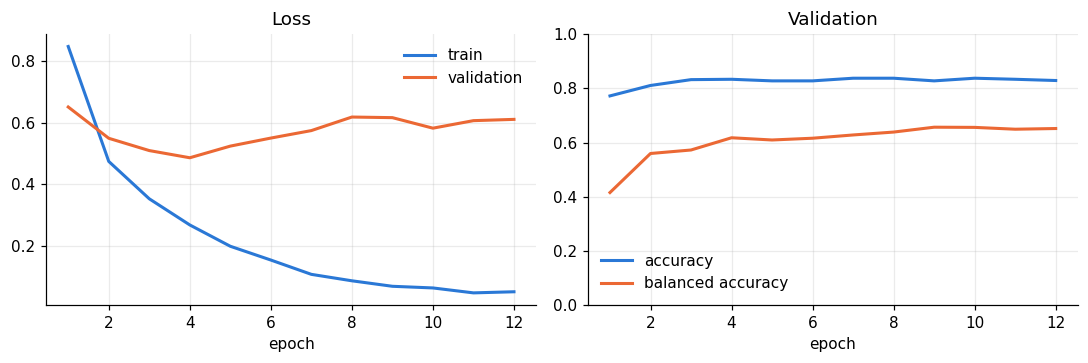

In [11]:
h = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(h.epoch, h.train_loss, lw=2, color="#2a78d6", label="train")
axes[0].plot(h.epoch, h.val_loss, lw=2, color="#eb6834", label="validation")
axes[0].set(title="Loss", xlabel="epoch"); axes[0].legend(frameon=False)
axes[1].plot(h.epoch, h.val_acc, lw=2, color="#2a78d6", label="accuracy")
axes[1].plot(h.epoch, h.val_bacc, lw=2, color="#eb6834", label="balanced accuracy")
axes[1].set(title="Validation", xlabel="epoch", ylim=(0, 1)); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## Predictions and embeddings for every image (best checkpoint)

One pass over all 10,015 images (train, val and test, so Phase II can use training images as
k-nearest neighbours). **Claims about model behaviour must use `split == "test"` only.**

In [12]:
best = torch.load(CKPT_DIR / "best.pt", map_location=DEVICE)
model.load_state_dict(best["model"]); model.eval()
print("using epoch", best["epoch"])

feats = {}
hook = model.avgpool.register_forward_hook(lambda m, i, o: feats.__setitem__("x", o.flatten(1)))
all_df = meta if not SMOKE_TEST else meta.groupby(["split", "dx"]).head(8).reset_index(drop=True)
dl_all = DataLoader(HamDataset(all_df, EVAL_TF), batch_size=BATCH, shuffle=False, num_workers=WORKERS)
probs, embs = [], []
with torch.no_grad():
    for x, _, _ in dl_all:
        with torch.autocast(DEVICE.type, enabled=use_amp):
            out = model(x.to(DEVICE))
        probs.append(torch.softmax(out.float(), 1).cpu().numpy())
        embs.append(feats["x"].float().cpu().numpy().astype(np.float16))
hook.remove()
probs, embs = np.concatenate(probs), np.concatenate(embs)

pred = all_df.copy().reset_index(drop=True)
for i, c in enumerate(CLASSES):
    pred[f"p_{c}"] = probs[:, i]
pred["label"] = pred.dx.map(C2I)
pred["pred"] = probs.argmax(1)
pred["pred_dx"] = [CLASSES[i] for i in pred.pred]
pred["correct"] = pred.pred == pred.label
pred["confidence"] = probs.max(1)
pred["p_true"] = probs[np.arange(len(pred)), pred.label]
pred["entropy"] = -(probs * np.log(probs + 1e-12)).sum(1)
pred["p_malignant"] = pred[[f"p_{c}" for c in MALIGNANT]].sum(axis=1)
pred["is_malignant"] = pred.dx.isin(MALIGNANT)
pred["checkpoint_epoch"] = best["epoch"]

using epoch 9


### Lesion area from the masks
Share of the 224 x 224 image covered by the lesion. A dataset property (not a model output), useful for slicing.

In [13]:
pred["lesion_area_frac"] = [
    (m.mean() if (m := load_mask(i)) is not None else np.nan) for i in pred.image_id]
pred.to_csv(OUT_DIR / "predictions_all.csv", index=False)
np.save(OUT_DIR / "embeddings_all.npy", embs)
print("saved", len(pred), "rows ->", OUT_DIR / "predictions_all.csv")
pred.groupby("split").correct.mean()

saved 10015 rows -> vis4ai_outputs/predictions_all.csv


split
test     0.829561
train    0.990976
val      0.827676
Name: correct, dtype: float64

## Shared starting visualisation: confusion matrix linked to thumbnails

The agreed entry point for Phase I. The matrix alone is **not** a finding; use the dropdowns to
open a cell and look at the images behind it. From here on, each pair builds its own views.

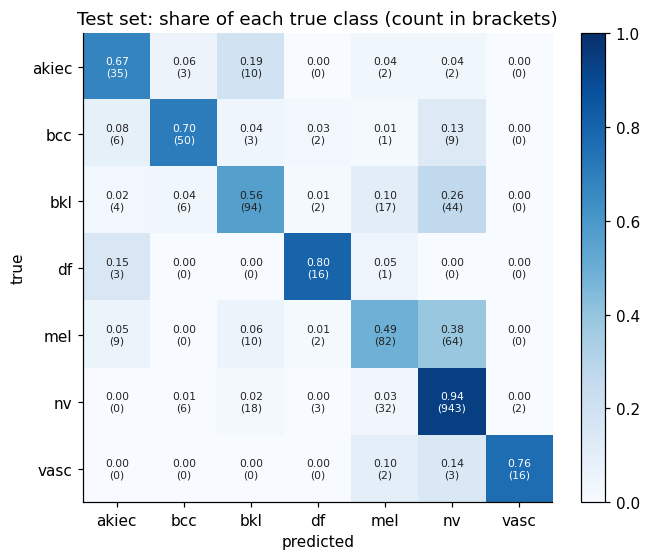

In [13]:
from sklearn.metrics import confusion_matrix
test = pred[pred.split == "test"].reset_index(drop=True)
cm = confusion_matrix(test.label, test.pred, labels=range(len(CLASSES)))
cm_row = cm / cm.sum(1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(cm_row, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES)), CLASSES); ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set(xlabel="predicted", ylabel="true", title="Test set: share of each true class (count in brackets)")
ax.grid(False)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f"{cm_row[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=7,
                color="white" if cm_row[i, j] > 0.6 else "#222")
fig.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

In [14]:
def show_gallery(df, n=24, cols=8, title=None, extra=None):
    """Thumbnails of the first n rows of df. `extra` = list of columns printed under each image."""
    df = df.head(n)
    if len(df) == 0:
        print("(no images)"); return
    rows = math.ceil(len(df) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.9, rows * 2.25), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), df.iterrows()):
        ax.imshow(load_image(r.image_id))
        lines = [f"{r.dx}" + (f" > {r.pred_dx} ({r.confidence:.2f})" if "pred_dx" in r else "")]
        for c in (extra or []):
            v = r[c]
            lines.append(f"{c}={v:.2f}" if isinstance(v, (float, np.floating)) else f"{c}={v}")
        ax.set_title("\n".join(lines), fontsize=7)
    if title: fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()

In [15]:
import ipywidgets as W
if IN_COLAB:
    from google.colab import output; output.enable_custom_widget_manager()

@W.interact(true_dx=W.Dropdown(options=CLASSES, value="mel"),
            pred_dx=W.Dropdown(options=CLASSES, value="nv"),
            sort_by=W.Dropdown(options=["confidence (high first)", "confidence (low first)"]),
            n=W.IntSlider(value=24, min=8, max=64, step=8))
def open_cell(true_dx, pred_dx, sort_by, n):
    cell = test[(test.dx == true_dx) & (test.pred_dx == pred_dx)]
    cell = cell.sort_values("confidence", ascending="low" in sort_by)
    print(f"{len(cell)} test images: true {true_dx} -> predicted {pred_dx}")
    show_gallery(cell, n=n, extra=["age", "sex", "localization"])

interactive(children=(Dropdown(description='true_dx', index=4, options=('akiec', 'bcc', 'bkl', 'df', 'mel', 'n…

## Done
Both pairs now open their own Phase I notebook, which reads `predictions_all.csv` from the shared Drive folder.
Do not re-train in the pair notebooks; everybody analyses this one model.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pred = pd.read_csv("predictions_all.csv")


test = pred[pred["split"] == "test"].copy()

display(test[["image_id", "dx", "pred_dx", "confidence"]].head())

,image_id,dx,pred_dx,confidence
6,ISIC_0029176,bkl,bkl,0.528132
7,ISIC_0029068,bkl,bcc,0.863412
8,ISIC_0025837,bkl,bkl,0.647244
9,ISIC_0025209,bkl,akiec,0.964666
18,ISIC_0029836,bkl,nv,0.951256


### I inspect randomly selected images of true nevi and compare them with melanomas misclassified as nevi. I focus on visual characteristics, such as color, shape, and border clarity, to explore possible reasons for the confusion.

Ordinary nevi: 811 unique lesions


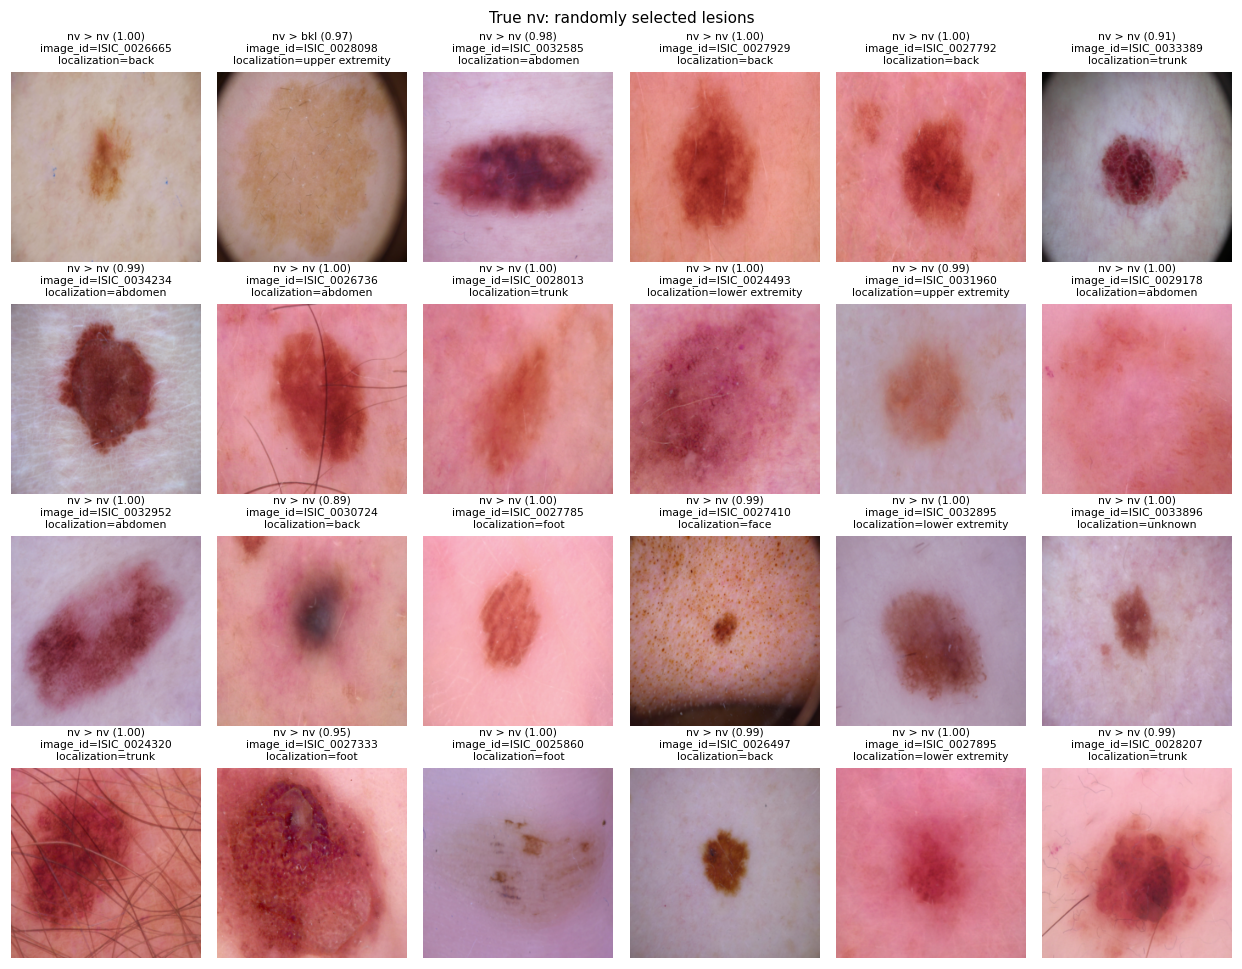

In [18]:
# Select test images whose true class is nv
# Include both correct and incorrect predictions
nv_images = test[test["dx"] == "nv"].copy()

# Shuffle the images with a fixed seed for reproducibility
# Keep one image per lesion to avoid showing the same lesion repeatedly
nv_images = (
    nv_images.sample(frac=1, random_state=42)
    .drop_duplicates("lesion_id")
)

# Print the number of unique lesions
print(f"Ordinary nevi: {len(nv_images)} unique lesions")

# Show 24 images in a grid with 6 columns
# Display the image ID and body site for each image
show_gallery(
    nv_images,
    n=24,
    cols=6,
    title="True nv: randomly selected lesions",
    extra=["image_id", "localization"]
)

In [19]:
# Count images with and without a lesion mask
print(test["has_mask"].value_counts(dropna=False))

has_mask
True    1502
Name: count, dtype: int64


### I inspect 12 randomly selected melanomas misclassified as nevi, with one image per lesion. I look for shared visual characteristics that may suggest explanations for the errors. These observations guide further analysis rather than establish systematic patterns.

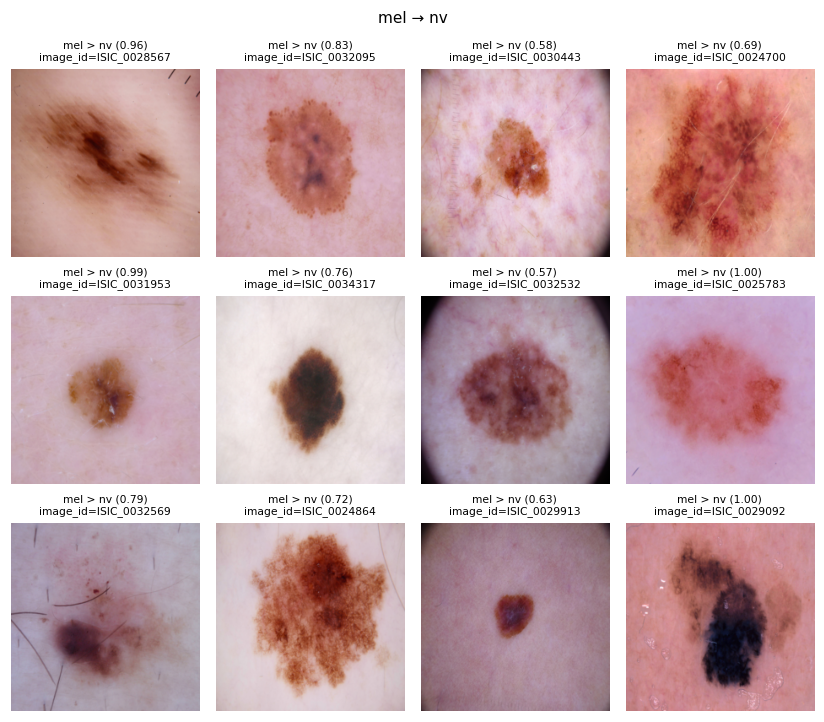

In [23]:
# Select mel images incorrectly predicted as nv
images = test[
    (test.dx == "mel") & (test.pred_dx == "nv")
]

# Shuffle and keep one image per lesion
images = (
    images.sample(frac=1, random_state=42)
    .drop_duplicates("lesion_id")
)

# Show image IDs above the pictures
show_gallery(
    images,
    n=12,
    cols=4,
    title="mel → nv",
    extra=["image_id"]
)

### I compare lesion brightness across correctly classified melanomas, melanomas misclassified as nevi, and correctly classified nevi. I measure average brightness within the lesion mask, using one image per lesion. The boxplots explore whether misclassified melanomas are lighter and more similar in brightness to nevi.

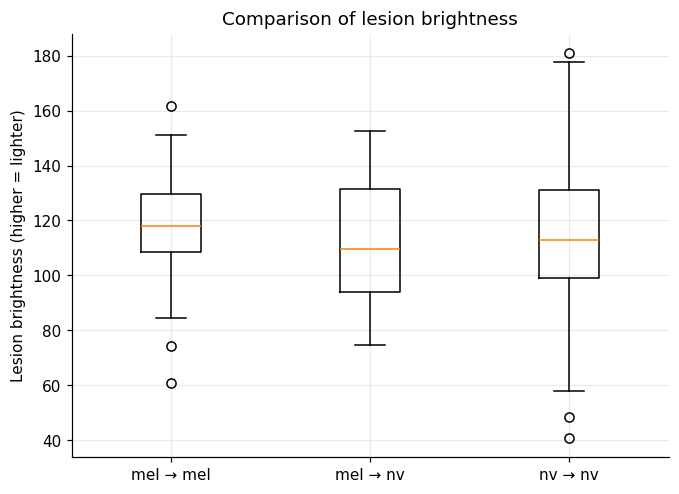

In [20]:
# Select three groups
groups = [
    test[(test.dx == "mel") & (test.pred_dx == "mel")],
    test[(test.dx == "mel") & (test.pred_dx == "nv")],
    test[(test.dx == "nv") & (test.pred_dx == "nv")]
]

results = []

for group in groups:
    values = []

    # Keep one image per lesion
    group = group.drop_duplicates("lesion_id")

    for image_id in group.image_id:
        image = load_image(image_id)
        mask = load_mask(image_id)

        if mask is None or not mask.any():
            continue

        # Convert RGB to brightness
        gray = (
            0.299 * image[:, :, 0]
            + 0.587 * image[:, :, 1]
            + 0.114 * image[:, :, 2]
        )

        # Average brightness inside the lesion
        values.append(gray[mask].mean())

    results.append(values)

# Compare the brightness distributions
plt.figure(figsize=(7, 5))
plt.boxplot(results)
plt.xticks([1, 2, 3], ["mel → mel", "mel → nv", "nv → nv"])
plt.ylabel("Lesion brightness (higher = lighter)")
plt.title("Comparison of lesion brightness")
plt.show()

### Among these samples, the melanomas (mel) that were misclassified as nevi (nv) had a lower median lesion brightness compared to the correctly identified melanomas, and their brightness values ​​were closer to those of the correctly identified nevi.

### I compare lesion shape across correctly classified melanomas, melanomas misclassified as nevi, and correctly classified nevi, using one image per lesion. I measure the major-to-minor axis ratio from the original lesion masks. Values closer to 1 indicate a rounder shape. The boxplots explore whether misclassified melanomas are rounder than correctly classified melanomas.

Note: you may need to restart the kernel to use updated packages.


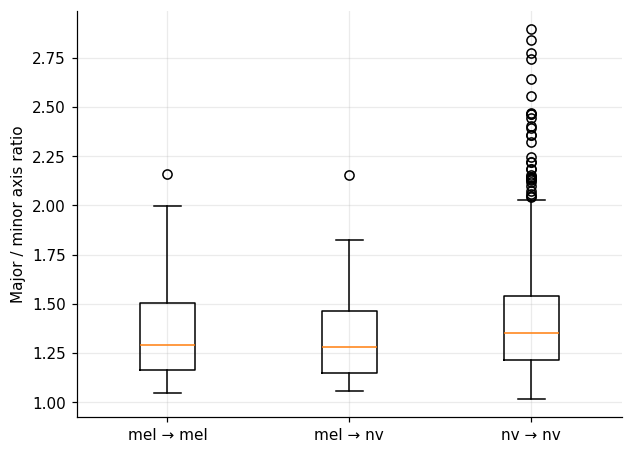

In [31]:
%pip install scikit-image
from skimage.measure import regionprops

results = []

for group in groups:
    ratios = []

    # Keep one image per lesion
    for image_id in group.drop_duplicates("lesion_id").image_id:
        mask = load_mask(image_id, size=None)

        if mask is None or not mask.any():
            continue

        # Treat the mask as one lesion
        shape = regionprops(mask.astype(int))[0]

        # Calculate the major-to-minor axis ratio
        if shape.axis_minor_length > 0:
            ratios.append(
                shape.axis_major_length / shape.axis_minor_length
            )

    results.append(ratios)

# Compare the three groups
plt.boxplot(results)
plt.xticks([1, 2, 3], ["mel → mel", "mel → nv", "nv → nv"])
plt.ylabel("Major / minor axis ratio")
plt.show()

### The mel instances misclassified as *nv* do not show a significant shift toward the nv category in terms of their overall elongation. Consequently, the aspect ratio—taken as a single metric—is insufficient to account for these misclassifications.

### I investigated whether lesions located in different positions are prone to significant classification errors.

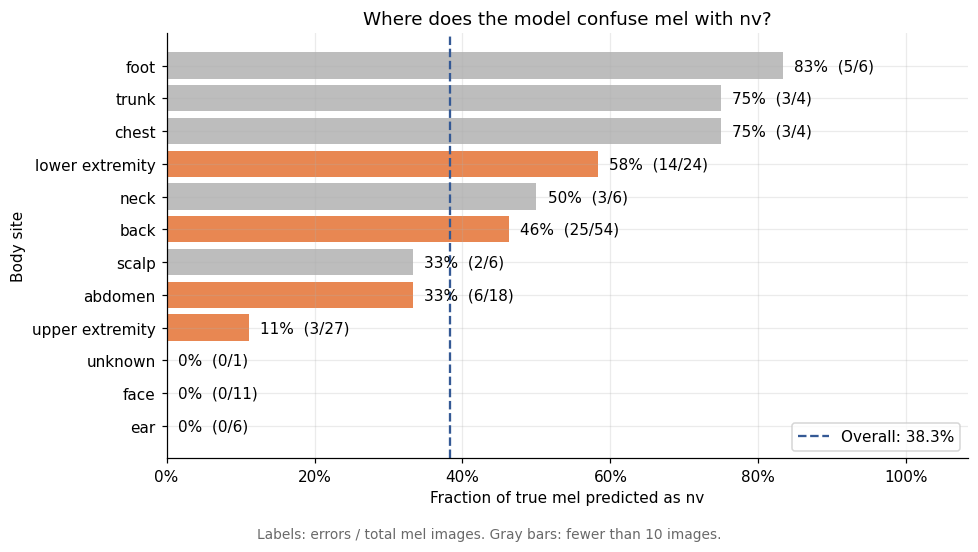

In [26]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Keep only test images whose true class is mel
mel_all = test[test["dx"] == "mel"].copy()

# Mark images predicted as nv
mel_all["to_nv"] = mel_all["pred_dx"] == "nv"
mel_all["localization"] = mel_all["localization"].fillna("unknown")

# Calculate sample counts, error counts, and error rates for each body site
by_site = (
    mel_all.groupby("localization")
    .agg(
        total=("to_nv", "size"),
        errors=("to_nv", "sum"),
        rate=("to_nv", "mean")
    )
    .sort_values("rate")
)

# Use gray for body sites with fewer than 10 images
colors = [
    "#BDBDBD" if n < 10 else "#E88752"
    for n in by_site["total"]
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(by_site.index, by_site["rate"], color=colors)

# Label each bar with the percentage and error count / total count
for i, (_, row) in enumerate(by_site.iterrows()):
    ax.text(
        row["rate"] + 0.015,
        i,
        f'{row["rate"]:.0%}  ({int(row["errors"])}/{int(row["total"])})',
        va="center",
        fontsize=10
    )

# Dashed line: overall fraction of test mel images predicted as nv
overall_rate = mel_all["to_nv"].mean()
ax.axvline(
    overall_rate,
    color="#345995",
    linestyle="--",
    label=f"Overall: {overall_rate:.1%}"
)

ax.set_xlim(0, max(0.65, by_site["rate"].max() + 0.25))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("Fraction of true mel predicted as nv")
ax.set_ylabel("Body site")
ax.set_title("Where does the model confuse mel with nv?")
ax.legend(loc="lower right")
ax.spines[["top", "right"]].set_visible(False)


fig.text(
    0.5, 0.01,
    "Labels: errors / total mel images. Gray bars: fewer than 10 images.",
    ha="center",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

### Many melanomas (MEL) on the lower extremities are misidentified as nevi (NV); upon reviewing images from the lower extremities, no clear distinguishing features were observed.

Lower limb: mel → nv, 11 unique lesions


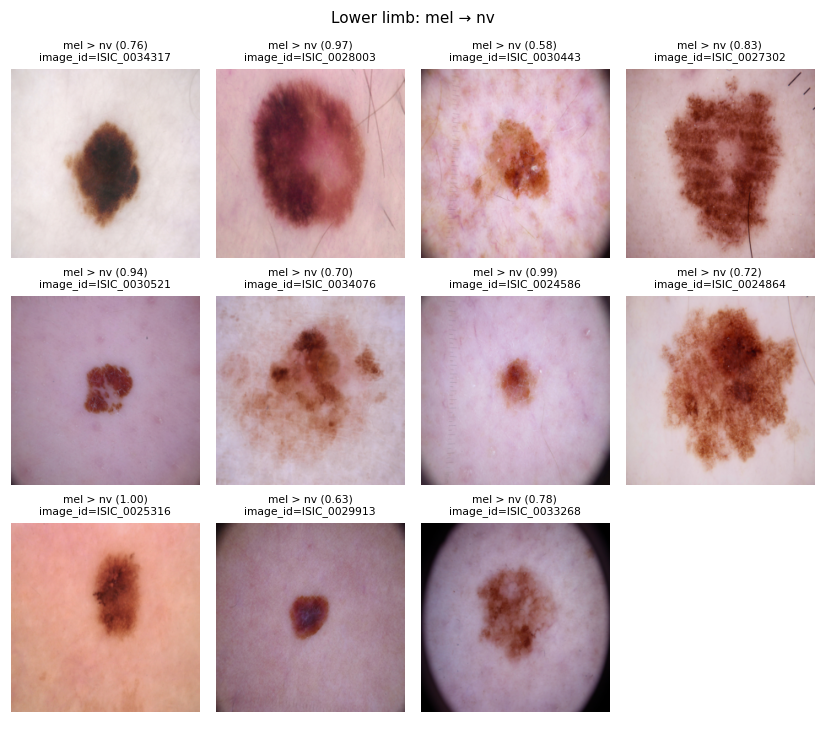

Lower limb: mel → mel, 8 unique lesions


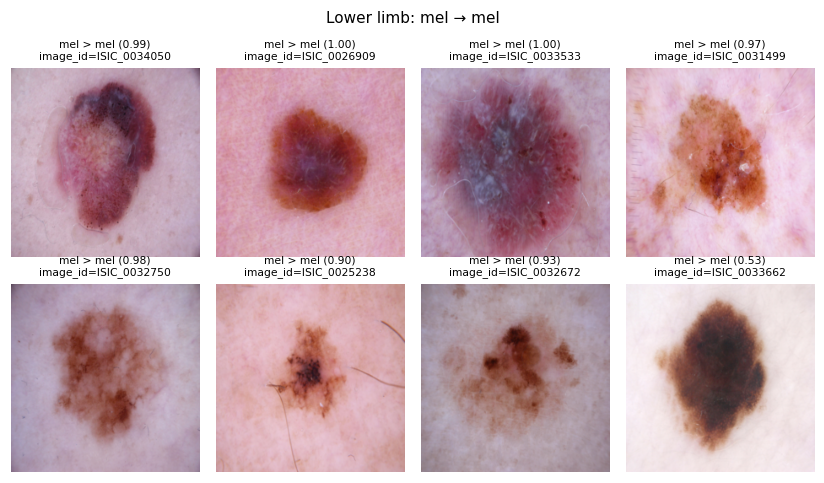

In [27]:
# Select true mel images from the lower extremity
lower_mel = test[
    (test["dx"] == "mel") &
    (test["localization"] == "lower extremity")
]

for prediction in ["nv", "mel"]:

    # Select the prediction group and keep one image per lesion
    images = (
        lower_mel[lower_mel["pred_dx"] == prediction]
        .sample(frac=1, random_state=42)
        .drop_duplicates("lesion_id")
    )

    print(f"Lower limb: mel → {prediction}, {len(images)} unique lesions")

    show_gallery(
        images,
        n=len(images),
        cols=4,
        title=f"Lower limb: mel → {prediction}",
        extra=["image_id"]
    )

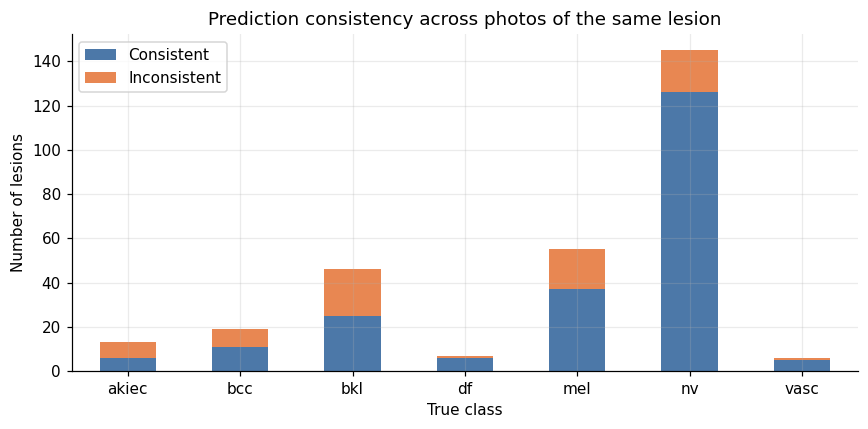

In [36]:
# Count consistent and inconsistent lesions in each class
counts = pd.crosstab(multi["dx"], multi["inconsistent"])
counts = counts.reindex(columns=[False, True], fill_value=0)
counts.columns = ["Consistent", "Inconsistent"]

# Show lesion counts in a stacked bar chart
counts.plot.bar(
    stacked=True,
    color=["#4C78A8", "#E88752"],
    figsize=(8, 4)
)

plt.xlabel("True class")
plt.ylabel("Number of lesions")
plt.title("Prediction consistency across photos of the same lesion")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### The model’s assessments of different images of the same lesion are not always consistent.